# 13 · The investment floor, and reinvestment at market prices

Notebook 11 calibrated the reinvestment elasticity at `η` = 1 and found `μ̂` = 0.13 at it, on a sample that had to drop every sector-year with a profit rate below a third of its country's average, because the power form `σ_c·(r̄/rᵢ)^η·Sᵢ` explodes as `rᵢ` → 0 and is undefined for losses. It left two gaps:

- **`η` was not available in the cross-dual system** (`market_prices = true`), whose profits at market prices can be negative, although that is the only system with an interior balanced growth path.
- **At `η` = 1 unprofitable sectors keep accumulating** at the average rate, so in the coupled system one sector's `k` explodes and its profit rate goes to zero.

The model now has a **linear reinvestment form** (`reinvestment_form = :linear`),

`reinvestmentᵢ = σ_c,ᵢ · [(1 − η)·Πᵢ + η·r̄_K·Kᵢ]`,   `r̄_K = ΣΠ/ΣK`,

which equals the fixed share at `η` = 0 and investment in proportion to capital at the average rate at `η` = 1, like the power form, but is defined for any sign of `Π`. With a common `σ_c` it leaves aggregate reinvestment at `σ_c·ΣΠ`. It is the form used with market prices. Two further options address the second gap: an **exit** of capital from unprofitable sectors (`exit_rate = φ`, `exit_hurdle = h`: `−φ·max(h·r̄ − rᵢ, 0)·Cᵢ`, scrapping) and an **investment floor** (`investment_floor = θ`: gross investment never falls below `θ·δᵢCᵢ`, the irreversibility of investment).

This notebook estimates all three on the full EU panel, loss years included, and asks whether the calibrated cross-dual economy of Portugal's market sectors has a stable interior balanced growth path. `estimate_investment_function(...; form = :linear, exit_hurdle)` and `estimate_investment_floor` (`src/mobility_estimation.jl`) do the estimation.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, DataFrames, Statistics, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. Investment when profits are low

The panel of notebook 11: the 15 market sectors of 26 EU countries (`data/eurostat_eu_sectors.csv`), gross investment `gk = 100·GFCFₜ/Cₜ₋₁`, depreciation `dk = 100·CFCₜ/Cₜ₋₁` and the profit rates of `t−1`. The linear form can use every row with a profit rate, including those with losses. First, what investment does at each level of relative profitability `r/r̄`: medians of gross investment, depreciation and net investment (all in % of capital), and the share of rows in which capital shrinks.

In [2]:
eu = CSV.read(joinpath("..", "..", "data", "eurostat_eu_sectors.csv"), DataFrame)
MARKET = setdiff(sort(String.(unique(eu.section))), NON_MARKET_SECTIONS)
IP = compute_investment_panel(eu; sections = MARKET)
@printf("%d rows; %d usable by the power form (r > 0), %d by the linear form, of which %d with losses\n",
        nrow(IP), count(IP.valid), count(IP.valid_linear), count(IP.valid_linear .& (IP.r .<= 0)))
IP.rel = IP.r ./ IP.rbar
IP.net = IP.gk .- IP.dk
edges = [-Inf, 0, 1/6, 1/3, 2/3, 1, 1.5, 3, Inf]
@printf("%-15s %6s │ %7s %7s %7s │ %9s\n", "r / r̄", "rows", "gross", "deprec.", "net", "shrinking")
for i in 1:length(edges)-1
    b = IP[(IP.rel .> edges[i]) .& (IP.rel .<= edges[i+1]) .& isfinite.(IP.net), :]
    @printf("(%5.2f, %5.2f] %6d │ %6.2f%% %6.2f%% %6.2f%% │ %8.0f%%\n", edges[i], edges[i+1], nrow(b),
            median(b.gk), median(b.dk), median(b.net), 100 * mean(b.net .< 0))
end

10665 rows; 9891 usable by the power form (r > 0), 10638 by the linear form, of which 585 with losses
r / r̄             rows │   gross deprec.     net │ shrinking


( -Inf,  0.00]    612 │   8.21%   7.67%   0.46% │       44%
( 0.00,  0.17]    708 │   8.08%   5.95%   1.62% │       25%


( 0.17,  0.33]    869 │   8.18%   6.32%   1.34% │       28%
( 0.33,  0.67]   1566 │   9.30%   7.07%   1.57% │       27%
( 0.67,  1.00]   1582 │  11.04%   9.00%   1.82% │       25%
( 1.00,  1.50]   2100 │  12.79%  10.31%   2.07% │       22%
( 1.50,  3.00]   2375 │  12.36%   9.82%   2.02% │       23%
( 3.00,   Inf]    853 │  14.02%  10.17%   2.76% │       24%


The linear form uses 10,638 rows, 747 more than the power form, 585 of them with losses.

**Investment falls with relative profitability, but it does not stop.** Sectors earning more than three times the average invest 14.0% of their capital gross; sectors with losses still invest 8.2%, more than their depreciation (7.7%). Their median net investment is +0.5% against +1.3% to +2.8% elsewhere, and 44% of the loss-making rows shrink, against 22–28% of the others. Capital leaves unprofitable sectors slowly, by not quite replacing what wears out, not by scrapping.

## 2. The linear form on every row

`estimate_investment_function(IP; form = :linear)` fits

`gk = λ · σ̄ᵢ · [(1 − η)·sk + η·100·r̄_K·Kᵢ/Cᵢ] + μ · gap + country × sector + country-year`,

where `K = C_{t−1} + V` (the `kv` column of `compute_investment_panel`). At a given `η` it is linear in `(λ, μ)`; the free estimate of `η` is `b/(a + b)` from the unrestricted fit, with a delta-method standard error. Notebook 11's trimmed power form is shown alongside for comparison.

In [3]:
lin = estimate_investment_function(IP; form = :linear)
pow = estimate_investment_function(IP; ratio_bounds = (1/3, 3))    # notebook 11's trimmed power form
u = lin.unrestricted
@printf("linear form, all %d rows:  λ = %.3f (se %.3f)   η = %.2f (se %.2f)   μ = %.3f (se %.3f)\n",
        lin.n, u.λ, u.se_λ, u.η, u.se_η, u.μ, u.se_μ)
@printf("%5s │ %22s │ %22s\n", "η", "linear, all rows: μ", "power, trimmed: μ")
for k in 1:nrow(lin.profile)
    @printf("%5.1f │ %8.3f (se %.3f) %+5.1f%% │ %8.3f (se %.3f) %+5.1f%%\n", lin.profile.η[k],
            lin.profile.μ[k], lin.profile.se_μ[k], 100 * (lin.profile.ssr[k] / minimum(lin.profile.ssr) - 1),
            pow.profile.μ[k], pow.profile.se_μ[k], 100 * (pow.profile.ssr[k] / minimum(pow.profile.ssr) - 1))
end

linear form, all 10638 rows:  λ = 0.097 (se 0.027)   η = 0.15 (se 0.18)   μ = 0.063 (se 0.011)
    η │    linear, all rows: μ │      power, trimmed: μ


  0.0 │    0.063 (se 0.011)  +0.0% │    0.046 (se 0.033)  +0.0%
  0.1 │    0.063 (se 0.011)  +0.0% │    0.055 (se 0.034)  +0.1%
  0.2 │    0.064 (se 0.011)  +0.0% │    0.064 (se 0.034)  +0.2%
  0.3 │    0.066 (se 0.011)  +0.0% │    0.074 (se 0.035)  +0.3%
  0.4 │    0.070 (se 0.011)  +0.1% │    0.084 (se 0.036)  +0.4%
  0.5 │    0.076 (se 0.012)  +0.3% │    0.094 (se 0.036)  +0.5%
  0.6 │    0.084 (se 0.013)  +0.5% │    0.104 (se 0.037)  +0.6%
  0.7 │    0.093 (se 0.013)  +0.8% │    0.112 (se 0.037)  +0.8%
  0.8 │    0.100 (se 0.014)  +1.1% │    0.118 (se 0.037)  +0.9%
  0.9 │    0.105 (se 0.014)  +1.3% │    0.123 (se 0.037)  +1.0%
  1.0 │    0.106 (se 0.015)  +1.4% │    0.127 (se 0.037)  +1.1%


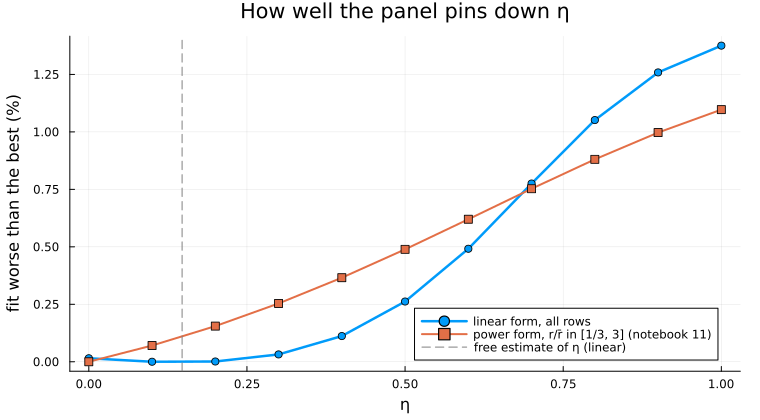

In [4]:
plot(lin.profile.η, 100 .* (lin.profile.ssr ./ minimum(lin.profile.ssr) .- 1); lw = 2.5, marker = :circle,
     label = "linear form, all rows", xlabel = "η", ylabel = "fit worse than the best (%)",
     title = "How well the panel pins down η")
plot!(pow.profile.η, 100 .* (pow.profile.ssr ./ minimum(pow.profile.ssr) .- 1); lw = 2, marker = :square,
      label = "power form, r/r̄ in [1/3, 3] (notebook 11)")
vline!([u.η]; color = :gray, ls = :dash, label = "free estimate of η (linear)")

**With the loss years in, the data favor a low `η`:** the free estimate is `η̂` = 0.15 (se 0.18), with `λ̂` = 0.097 and `μ̂` = 0.063 (se 0.011). `η` is still weakly identified (the fit is at most 1.4% worse at `η` = 1), but now the profile has its minimum near 0.1–0.2, and values above about 0.5 are more than two standard errors away. Notebook 11 did not read `η` off a fit: with the power form the trimmed profile is nearly flat (it is least bad at `η` = 0 and only 1.1% worse at 1), and it calibrated `η` = 1 from the small margin `λ`, assuming the model's average level `λ = 1`. Here `λ` stays free, as in notebook 11's section 2, and the data choose between own surplus and the average return on capital directly. They choose own surplus.

`μ̂` rises with `η` on both forms, from 0.063 to 0.106 (linear) and from 0.046 to 0.127 (power), so the low `η` also means a lower mobility coefficient: about 0.06, a fifth of the model's default 0.3.

## 3. Exit, or a floor?

Section 1 suggests the two candidates for what happens when profits collapse. An **exit** term adds `−φ·100·max(h·r̄ − r, 0)·K/C` to the regression: capital shrinks in proportion to how far the profit rate is below a hurdle `h·r̄` (`h` = 0: losses only). A **floor** says gross investment does not fall below a share `θ` of depreciation: `estimate_investment_floor` regresses `gk` on `dk` through the origin on the rows below a profitability threshold, with country-clustered errors, and also reports the median of `gk/dk` there.

In [5]:
@printf("%-26s │ %18s │ %16s\n", "exit hurdle h", "φ (exit rate)", "μ")
for h in (0.0, 1/3, 1/2, 1.0)
    e = estimate_investment_function(IP; form = :linear, exit_hurdle = h).unrestricted
    @printf("%-26s │ %7.3f (se %.3f) │ %6.3f (se %.3f)\n", @sprintf("losses below %.2f·r̄", h), e.φ, e.se_φ, e.μ, e.se_μ)
end
println()
IPi = compute_investment_panel(eu; sections = MARKET, self_employed = :imputed)
for (lab, P, b) in (("losses (r ≤ 0)", IP, 0.0), ("r ≤ r̄/6", IP, 1/6), ("r ≤ r̄/3", IP, 1/3),
                    ("losses, self-employed imputed", IPi, 0.0))
    f = estimate_investment_floor(P; below = b)
    @printf("floor from %-30s θ = %.2f (se %.2f), median gross/depreciation %.2f, %d rows\n", lab, f.θ, f.se, f.median_ratio, f.n)
end
θ̂ = round(estimate_investment_floor(IP).θ, digits = 2)

exit hurdle h              │      φ (exit rate) │                μ
losses below 0.00·r̄        │  -0.323 (se 0.116) │  0.065 (se 0.011)


losses below 0.33·r̄        │  -0.159 (se 0.086) │  0.066 (se 0.011)
losses below 0.50·r̄        │  -0.085 (se 0.084) │  0.066 (se 0.011)


losses below 1.00·r̄        │  -0.010 (se 0.047) │  0.065 (se 0.012)

floor from losses (r ≤ 0)                 θ = 0.69 (se 0.18), median gross/depreciation 1.06, 612 rows
floor from r ≤ r̄/6                        θ = 0.83 (se 0.19), median gross/depreciation 1.18, 1320 rows


floor from r ≤ r̄/3                        θ = 0.92 (se 0.17), median gross/depreciation 1.19, 2189 rows
floor from losses, self-employed imputed  θ = 0.96 (se 0.15), median gross/depreciation 1.12, 1809 rows


0.69

**There is no exit through investment.** `φ̂` has the wrong sign at every hurdle: −0.32 (se 0.12) for losses only, −0.16 at a third of the average, −0.09 at half, and zero at the average itself. Holding the profit-rate gap fixed, the further a sector's profit rate is below the hurdle the *more* it invests relative to capital, not less, and `μ` stays at 0.065 whatever the hurdle. The exit term stays in the model as a tool for scenarios (scrapping after a crisis, say), not as an estimate.

**There is a floor near replacement.** In the loss-making rows gross investment is 0.69 of depreciation (se 0.18), and the median row invests 1.06 times its depreciation. The less strictly the rows are selected, the closer the floor gets to full replacement: 0.83 below a sixth of the average, 0.92 below a third, and 0.96 when the self-employed's labor income is imputed (which puts 1,809 rows in loss). Gross investment does not go below about 70–100% of depreciation even when a sector loses money.

## 4. Robustness

The linear form and the floor, on the variants of notebooks 11 and 12: the self-employed imputed, without Ireland and Luxembourg, and before and after 2008.

In [6]:
cases = [("baseline", IP), ("self-employed imputed", IPi),
         ("without IE and LU", IP[.!in.(IP.geo, Ref(["IE", "LU"])), :]),
         ("up to 2008", IP[IP.year .<= 2008, :]), ("2009 on", IP[IP.year .>= 2009, :])]
@printf("%-24s │ %16s │ %16s │ %16s │ %16s\n", "", "λ", "η", "μ", "floor θ")
for (lab, P) in cases
    e = estimate_investment_function(P; form = :linear).unrestricted
    f = estimate_investment_floor(P)
    @printf("%-24s │ %6.3f (se %.3f) │ %6.2f (se %.2f) │ %6.3f (se %.3f) │ %6.2f (se %.2f)\n",
            lab, e.λ, e.se_λ, e.η, e.se_η, e.μ, e.se_μ, f.θ, f.se)
end

                         │                λ │                η │                μ │          floor θ
baseline                 │  0.097 (se 0.027) │   0.15 (se 0.18) │  0.063 (se 0.011) │   0.69 (se 0.18)


self-employed imputed    │  0.047 (se 0.019) │   0.45 (se 0.23) │  0.095 (se 0.011) │   0.96 (se 0.15)
without IE and LU        │  0.078 (se 0.030) │   0.09 (se 0.24) │  0.068 (se 0.011) │   0.66 (se 0.17)


up to 2008               │  0.024 (se 0.025) │  -1.53 (se 1.87) │  0.078 (se 0.014) │   0.59 (se 0.15)
2009 on                  │  0.217 (se 0.056) │   0.26 (se 0.11) │  0.062 (se 0.013) │   1.05 (se 0.09)


`μ̂` is 0.06–0.10 in every variant and `λ̂` small everywhere. `η̂` stays low without Ireland and Luxembourg (0.09) and from 2009 (0.26, se 0.11), and is higher with the self-employed imputed (0.45, se 0.23); `η` = 1 lies more than two standard errors away in all three. Up to 2008 it is not identified at all (−1.53, se 1.87), because `λ̂` is near zero (0.024): when investment barely follows the surplus term, its split between own surplus and average return cannot be told apart. The floor is 0.59–1.05 in every variant, highest (1.05, se 0.09) from 2009.

## 5. Balanced growth with market prices

Portugal's 15 market sectors in 2019, with notebook 11's departments (each sector's own gross reinvestment share `σ̄ᵢ` as its `σ_c`, capped at 0.85, `σ_v` = 0.1), now in the cross-dual system with the linear form. For each `η` on the grid, with the `μ` its profile gives, `balanced_growth` finds the balanced growth path and its stability (largest real part of the Jacobian's eigenvalues in the normalized system). The table also shows the growth rate `g`, the smallest share of capital (`C` or `V`) of any sector and the capital-weighted dispersion of profit rates on the path.

In [7]:
P19 = eu[(eu.geo .== "PT") .& (eu.year .== 2019), :]
σbar_pt = Dict(zip(IP.section[IP.geo .== "PT"], IP.σbar[IP.geo .== "PT"]))
depts = map(MARKET) do s
    row = P19[P19.section .== s, :][1, :]
    S = row.GVA - row.compensation - row.CFC
    Department(String(s); c = row.capital_stock, v = row.compensation, e = max(S / row.compensation, 0.1),
               σ_c = min(σbar_pt[s], 0.85), σ_v = 0.1, δ = row.CFC / row.capital_stock)
end
N = length(depts)
η̂, μ̂ = round(u.η, digits = 2), round(u.μ, digits = 2)
sol0, _, p = simulate_Ndept_custom(deepcopy(depts); T = 1.0, seed = 1, coupled = true, market_prices = true,
                                   reinvestment_form = :linear, η = η̂, μ = μ̂)
"""Dispersion of profit rates (capital-weighted sd) at a full cross-dual state."""
function dispersion(X, p)
    C, V = X[1:N], X[N+1:2N]
    ec = cross_dual_state(C, V, X[2N+1:3N], p)
    K = C .+ V; r̄ = sum(ec.r .* K) / sum(K)
    sqrt(sum(K .* (ec.r .- r̄) .^ 2) / sum(K))
end
sweep = map(eachrow(lin.profile)) do row
    q = merge(p, (η = row.η, μ = row.μ))
    eq = balanced_growth(q, sol0.u[1])
    (η = row.η, μ = row.μ, converged = eq.converged, stable = eq.stable, g = eq.g,
     max_re = maximum(real.(eq.eigenvalues)), min_share = minimum(eq.X[1:2N]), dispersion = dispersion(eq.X, q))
end |> DataFrame
@printf("%4s %6s │ %9s %6s %7s %9s %10s %10s\n", "η", "μ(η)", "converged", "stable", "g", "max Re λ", "min share", "dispersion")
for r in eachrow(sweep)
    @printf("%4.1f %6.3f │ %9s %6s %6.2f%% %9.4f %10.5f %10.3f\n", r.η, r.μ, r.converged, r.stable, 100r.g, r.max_re, r.min_share, r.dispersion)
end

   η   μ(η) │ converged stable       g  max Re λ  min share dispersion
 0.0  0.063 │      true   true   7.23%   -0.0391    0.00182      0.066


 0.1  0.063 │      true   true   7.23%   -0.0433    0.00179      0.070
 0.2  0.064 │      true   true   7.24%   -0.0481    0.00176      0.074
 0.3  0.066 │      true   true   7.25%   -0.0533    0.00172      0.079
 0.4  0.070 │      true   true   7.26%   -0.0590    0.00168      0.084
 0.5  0.076 │      true   true   7.27%   -0.0526    0.00163      0.090
 0.6  0.084 │      true   true   7.28%   -0.0410    0.00158      0.096
 0.7  0.093 │      true   true   7.29%   -0.0300    0.00152      0.105
 0.8  0.100 │      true   true   7.31%   -0.0202    0.00144      0.116
 0.9  0.105 │      true   true   7.36%   -0.0132    0.00133      0.132
 1.0  0.106 │     false   true   7.58%   -0.0115   -0.00115      0.158


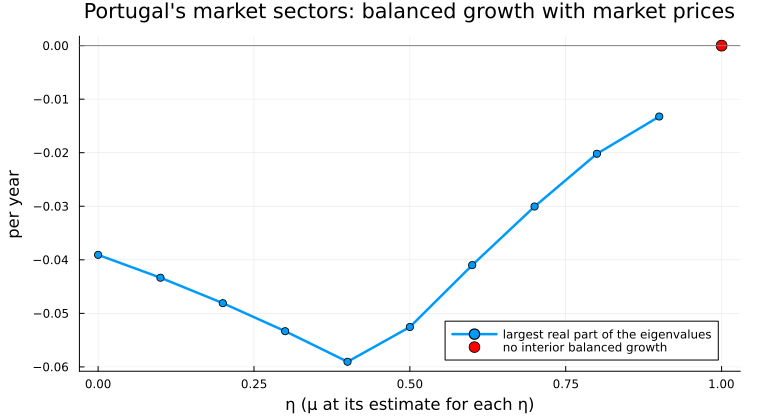

In [8]:
ok = sweep.converged .& (sweep.min_share .> 0)
plot(sweep.η[ok], sweep.max_re[ok]; lw = 2.5, marker = :circle, label = "largest real part of the eigenvalues",
     xlabel = "η (μ at its estimate for each η)", ylabel = "per year", title = "Portugal's market sectors: balanced growth with market prices")
scatter!(sweep.η[.!ok], zeros(count(.!ok)); color = :red, ms = 6, label = "no interior balanced growth")
hline!([0]; color = :gray, label = "")

**For every `η` up to 0.9 the economy has a stable interior balanced growth path**: the growth rate is 7.2–7.4%, every sector keeps a positive share of capital, and the largest real part of the eigenvalues stays negative, from −0.039 at `η` = 0 down to −0.059 at 0.4 and back up to −0.013 at 0.9. Raising `η` widens the dispersion of profit rates on the path (0.066 at `η` = 0, 0.132 at 0.9), since a sector's reinvestment depends less on its own profits, and it slows the return to the path.

**At `η` = 1 there is no interior balanced growth path**: Newton's method fails and the nearest point has a negative share (−0.0012). At the estimated `η` the economy is far from that boundary, with the fastest return to the path near `η` = 0.4.

## 6. Two hundred years

The same economy simulated from the 2019 data, at the fixed share, at the estimate (`η` = 0.15) and at notebook 11's `η` = 1, with `μ` rounded to two decimals from the linear profile at each.

fixed share          η = 0.00 μ = 0.06: year 200 dispersion 0.066, largest share 0.21 (C), lowest r 0.115 (E)
estimated            η = 0.15 μ = 0.06: year 200 dispersion 0.072, largest share 0.21 (C), lowest r 0.105 (E)


η = 1 (notebook 11)  η = 1.00 μ = 0.11: year 200 dispersion 0.152, largest share 0.32 (E), lowest r -0.001 (E)


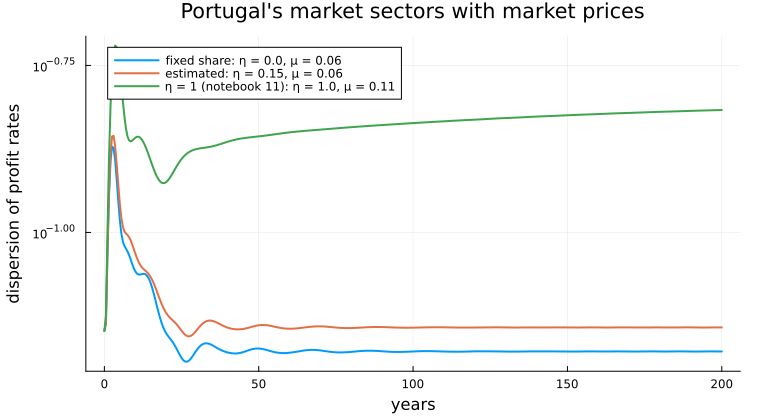

In [9]:
runs = [("fixed share", 0.0, round(lin.profile.μ[1], digits = 2)), ("estimated", η̂, μ̂),
        ("η = 1 (notebook 11)", 1.0, round(lin.profile.μ[end], digits = 2))]
plt = plot(xlabel = "years", ylabel = "dispersion of profit rates", yscale = :log10, legend = :topleft,
           title = "Portugal's market sectors with market prices")
for (lab, η, μ) in runs
    sol, _, q = simulate_Ndept_custom(deepcopy(depts); T = 200.0, seed = 1, coupled = true, market_prices = true,
                                      reinvestment_form = :linear, η = η, μ = μ)
    d = [dispersion(X, q) for X in sol.u]
    plot!(plt, sol.t, d; lw = 2, label = "$lab: η = $η, μ = $μ")
    X = sol.u[end]; C = X[1:N]; ec = cross_dual_state(C, X[N+1:2N], X[2N+1:3N], q); k = argmax(C)
    @printf("%-20s η = %.2f μ = %.2f: year 200 dispersion %.3f, largest share %.2f (%s), lowest r %.3f (%s)\n",
            lab, η, μ, d[end], C[k] / sum(C), MARKET[k], minimum(ec.r), MARKET[argmin(ec.r)])
end
plt

At the fixed share and at the estimate the dispersion of profit rates settles at 0.066 and 0.072 within about 60 years, manufacturing (C) has the largest share of constant capital (0.21), and the lowest profit rate, energy and water (E)'s, stays above 10%. At `η` = 1 the economy drifts instead: E takes 32% of constant capital while its profit rate falls to zero, and the dispersion is still rising at year 200 (0.152). Notebook 11's problem with `η` = 1 is not a matter of the coupled system: it is the same with market prices.

## 7. When the floor binds

On the balanced growth path at the estimates no sector loses money, so the floor never binds. It matters in transitions. Starting from the path, manufacturing's market price falls by 40% (−0.5 in logs): its profit rate drops from 0.152 to −0.067. Manufacturing's share of constant capital relative to the path, over 30 years, without the floor and with it at the estimated `θ` and at full replacement.

after the shock manufacturing's profit rate is -0.067 (balanced growth: 0.152)
no floor                     lowest share 0.818 of balanced growth, at year 2.2; losses for 0.7 years; year 30: 1.001


floor θ = 0.69 (estimated)   lowest share 0.836 of balanced growth, at year 2.4; losses for 0.7 years; year 30: 1.001
floor θ = 1                  lowest share 0.850 of balanced growth, at year 2.5; losses for 0.8 years; year 30: 1.002


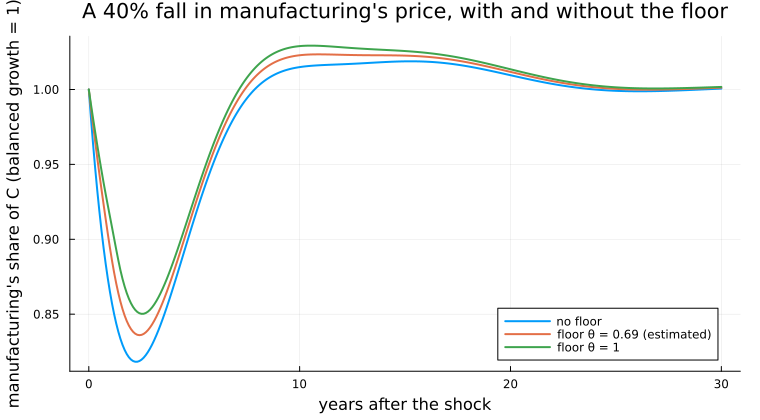

In [10]:
eq = balanced_growth(p, sol0.u[1])
j = findfirst(==("C"), MARKET)
X0 = copy(eq.X); X0[2N + j] -= 0.5           # manufacturing's price falls by 40%
ec = cross_dual_state(X0[1:N], X0[N+1:2N], X0[2N+1:3N], p)
@printf("after the shock manufacturing's profit rate is %.3f (balanced growth: %.3f)\n", ec.r[j],
        cross_dual_state(eq.X[1:N], eq.X[N+1:2N], eq.X[2N+1:3N], p).r[j])
plt = plot(xlabel = "years after the shock", ylabel = "manufacturing's share of C (balanced growth = 1)",
           title = "A 40% fall in manufacturing's price, with and without the floor")
for (lab, θ) in (("no floor", nothing), ("floor θ = $θ̂ (estimated)", θ̂), ("floor θ = 1", 1.0))
    q = isnothing(θ) ? p : merge(p, (investment_floor = θ,))
    s = solve(ODEProblem(cross_dual_system!, X0, (0.0, 30.0), q), Tsit5(), saveat = 0.1)
    share = [X[j] / sum(X[1:N]) for X in s.u] ./ (eq.X[j] / sum(eq.X[1:N]))
    losses = count(X -> cross_dual_state(X[1:N], X[N+1:2N], X[2N+1:3N], q).Π[j] < 0, s.u) * 0.1
    plot!(plt, s.t, share; lw = 2, label = lab)
    @printf("%-28s lowest share %.3f of balanced growth, at year %.1f; losses for %.1f years; year 30: %.3f\n",
            lab, minimum(share), s.t[argmin(share)], losses, share[end])
end
plt

The fall takes manufacturing's share of capital to 0.82 of its balanced-growth value after 2.2 years without the floor, and to 0.84 with `θ` = 0.69 (0.85 with `θ` = 1). Manufacturing makes losses for less than a year in each case, because its price recovers as its output falls short of demand, and by year 30 its share is back on the path (1.001–1.002). **The floor dampens the fall of capital after a shock by a tenth at the estimated `θ` and by about a sixth at full replacement, and changes nothing on the balanced growth path.**

## What the full panel says

- **Investment does not stop when profits do.** Loss-making sectors still invest 8.2% of their capital gross, 1.06 times their depreciation at the median; capital leaves them slowly, by under-replacement.
- **With the loss years in, `η̂` = 0.15** (se 0.18; up to about 0.5 within two standard errors, 0.09–0.45 across variants) and **`μ̂` ≈ 0.06**. The data put own surplus first, not the average return. Notebook 11's `η` = 1 was a calibration from the margin, not an estimate.
- **There is no exit through investment** (`φ̂` < 0 at every hurdle). The exit term is a scenario tool.
- **There is an irreversibility floor**: gross investment ≥ `θ`·depreciation with `θ̂` = 0.69 (se 0.18) in the loss years, 0.6–1.05 across samples. It binds only in transitions after shocks.
- **The calibrated economy is well behaved.** With market prices, Portugal's market sectors have a stable interior balanced growth path for every `η` up to 0.9, and at the estimates the dispersion of profit rates settles at about 0.07. Only at `η` = 1 does capital drift into one sector, with or without market prices.